In [ ]:
# ============================================================
# AI201 MACHINE LEARNING PROJECT
#
# Does Removing or Down-Weighting Anomalous User Interactions
# Improve Product Recommendation Quality?
#
# Dataset: RetailRocket Recommender System Dataset
# ============================================================

import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ------------------------------------------------------------
# FILE PATHS
# ------------------------------------------------------------

EVENTS_PATH = "data/events.csv"
ITEM_PROPERTIES_1_PATH = "data/item_properties_part1.csv"
ITEM_PROPERTIES_2_PATH = "data/item_properties_part2.csv"
CATEGORY_TREE_PATH = "data/category_tree.csv"

# ------------------------------------------------------------
# OUTPUT
# ------------------------------------------------------------

OUTPUT_DIR = "results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ------------------------------------------------------------
# EXPERIMENT CONFIGURATION
# ------------------------------------------------------------

K_VALUES = [5, 10]

# Popularity candidate pool
CANDIDATE_POOL = 1000

# Hyperparameters selected using validation set
CONTAMINATION_GRID = [0.01, 0.03, 0.05, 0.10]

# Minimum weight for strongly anomalous users
MIN_ANOMALY_WEIGHT = 0.25

# Isolation Forest sample size
ANOMALY_SAMPLE_SIZE = 150_000

In [ ]:
# ============================================================
# LOAD DATA
# ============================================================

events = pd.read_csv(EVENTS_PATH)

item_properties_1 = pd.read_csv(
    ITEM_PROPERTIES_1_PATH
)

item_properties_2 = pd.read_csv(
    ITEM_PROPERTIES_2_PATH
)

category_tree = pd.read_csv(
    CATEGORY_TREE_PATH
)

print("EVENTS")
print(events.shape)
print(events.columns.tolist())

print("\nITEM PROPERTIES PART 1")
print(item_properties_1.shape)
print(item_properties_1.columns.tolist())

print("\nITEM PROPERTIES PART 2")
print(item_properties_2.shape)
print(item_properties_2.columns.tolist())

print("\nCATEGORY TREE")
print(category_tree.shape)
print(category_tree.columns.tolist())

EVENTS
(1410512, 5)
['timestamp', 'visitorid', 'event', 'itemid', 'transactionid']

ITEM PROPERTIES PART 1
(1001126, 4)
['timestamp', 'itemid', 'property', 'value']

ITEM PROPERTIES PART 2
(1140936, 4)
['timestamp', 'itemid', 'property', 'value']

CATEGORY TREE
(1669, 2)
['categoryid', 'parentid']


In [ ]:
# ============================================================
# BASIC DATA INSPECTION
# ============================================================

print("Events:")
display(events.head())

print("\nItem properties:")
display(item_properties_1.head())

print("\nCategory tree:")
display(category_tree.head())

print("\nMissing values in events:")
print(events.isnull().sum())

print("\nEvent types:")
print(events["event"].value_counts())

print("\nNumber of users:")
print(events["visitorid"].nunique())

print("\nNumber of items:")
print(events["itemid"].nunique())

Events:


,timestamp,visitorid,event,itemid,transactionid
0,1433221332117,257597,view,355908.0,NaN
1,1433224214164,992329,view,248676.0,NaN
2,1433221999827,111016,view,318965.0,NaN
3,1433221955914,483717,view,253185.0,NaN
4,1433221337106,951259,view,367447.0,NaN



Item properties:


,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513



Category tree:


,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0



Missing values in events:
timestamp              0
visitorid              0
event                  0
itemid                 1
transactionid    1398923
dtype: int64

Event types:
event
view           1362849
addtocart        36074
transaction      11589
Name: count, dtype: int64

Number of users:
749562

Number of items:
181247


In [ ]:
# ============================================================
# EVENT PREPROCESSING
# ============================================================

events = events.drop_duplicates().copy()

events = events[
    events["event"].isin(
        ["view", "addtocart", "transaction"]
    )
].copy()

events["datetime"] = pd.to_datetime(
    events["timestamp"],
    unit="ms"
)

events = events.sort_values(
    "timestamp"
).reset_index(drop=True)

print("Cleaned events:", events.shape)

print("\nEvent distribution:")
print(events["event"].value_counts())

print("\nUnique users:",
      events["visitorid"].nunique())

print("Unique items:",
      events["itemid"].nunique())

print("\nTime range:")
print(events["datetime"].min())
print(events["datetime"].max())

Cleaned events: (1410267, 6)

Event distribution:
event
view           1362798
addtocart        35880
transaction      11589
Name: count, dtype: int64

Unique users: 749562
Unique items: 181247

Time range:
2015-06-01 06:00:09.198000
2015-09-15 05:59:07.597000


event
view           1362798
addtocart        35880
transaction      11589
Name: count, dtype: int64


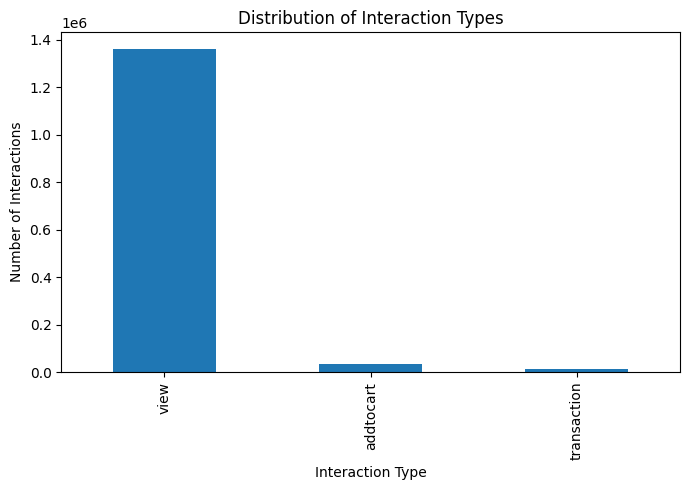

In [ ]:
# ============================================================
# EVENT DISTRIBUTION
# ============================================================

event_counts = events["event"].value_counts()

print(event_counts)

plt.figure(figsize=(7, 5))

event_counts.plot(kind="bar")

plt.title("Distribution of Interaction Types")
plt.xlabel("Interaction Type")
plt.ylabel("Number of Interactions")

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/event_distribution.png",
    dpi=200
)

plt.show()

count    749562.000000
mean          1.881455
std          10.192538
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
max        4488.000000
dtype: float64


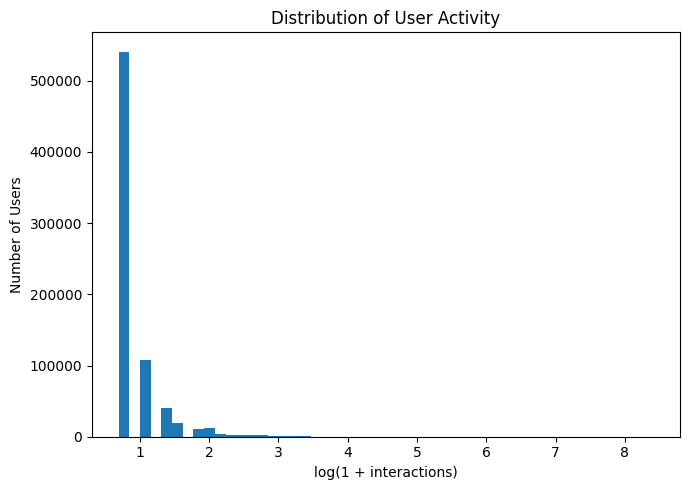

In [ ]:
# ============================================================
# USER ACTIVITY
# ============================================================

user_activity = (
    events
    .groupby("visitorid")
    .size()
)

print(user_activity.describe())

plt.figure(figsize=(7, 5))

plt.hist(
    np.log1p(user_activity),
    bins=50
)

plt.title("Distribution of User Activity")
plt.xlabel("log(1 + interactions)")
plt.ylabel("Number of Users")

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/user_activity.png",
    dpi=200
)

plt.show()

count    181247.000000
mean          7.780907
std          23.353646
min           1.000000
25%           1.000000
50%           2.000000
75%           6.000000
max        3281.000000
dtype: float64


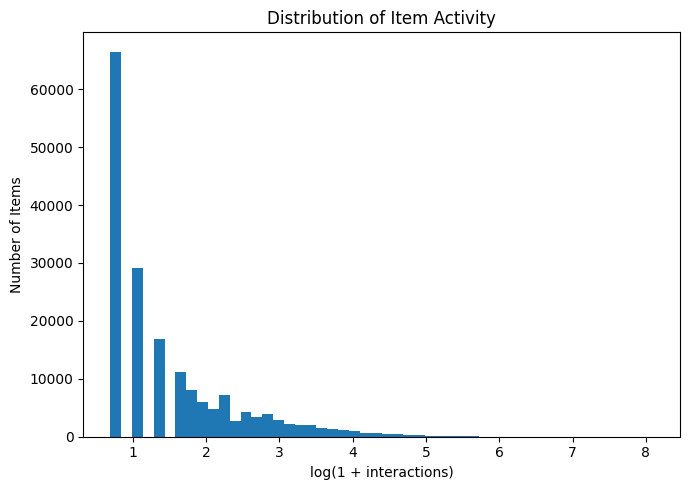

In [ ]:
# ============================================================
# ITEM ACTIVITY
# ============================================================

item_activity = (
    events
    .groupby("itemid")
    .size()
)

print(item_activity.describe())

plt.figure(figsize=(7, 5))

plt.hist(
    np.log1p(item_activity),
    bins=50
)

plt.title("Distribution of Item Activity")
plt.xlabel("log(1 + interactions)")
plt.ylabel("Number of Items")

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/item_activity.png",
    dpi=200
)

plt.show()

In [ ]:
# ============================================================
# COMBINE ITEM PROPERTY FILES
# ============================================================

item_properties = pd.concat(
    [
        item_properties_1,
        item_properties_2
    ],
    ignore_index=True
)

item_properties = item_properties.drop_duplicates()

print(
    "Combined item properties:",
    item_properties.shape
)

display(item_properties.head())

Combined item properties: (2142062, 4)


,timestamp,itemid,property,value
0,1435460400000,460429,categoryid,1338
1,1441508400000,206783,888,1116713 960601 n277.200
2,1439089200000,395014,400,n552.000 639502 n720.000 424566
3,1431226800000,59481,790,n15360.000
4,1431831600000,156781,917,828513


The item-property data is in a long format:

itemid | property | value

In [ ]:
# ============================================================
# ITEM PROPERTY ANALYSIS
# ============================================================

print(
    "Number of unique properties:",
    item_properties["property"].nunique()
)

print("\nMost common properties:")

print(
    item_properties["property"]
    .value_counts()
    .head(20)
)

print("\nUnique items with properties:")

print(
    item_properties["itemid"].nunique()
)

Number of unique properties: 1064

Most common properties:
property
888           317578
790           189804
available     158021
categoryid     83012
6              66967
283            62922
776            60760
678            50421
364            50070
202            47162
159            44232
839            44175
764            44137
112            44111
917            44089
227            36475
698            30720
451            28056
663            25254
962            25020
Name: count, dtype: int64

Unique items with properties:
401635


In [ ]:
# ============================================================
# ITEM PROPERTY FEATURES
# ============================================================

item_features = (
    item_properties
    .groupby("itemid")
    .agg(
        num_properties=("property", "nunique"),
        num_property_values=("value", "nunique")
    )
)

item_features.head()

,num_properties,num_property_values
itemid,,
0,5,5
1,5,5
2,2,2
3,2,2
4,3,3


In [ ]:
# ============================================================
# CATEGORY FEATURES
# ============================================================

print(category_tree.columns)

display(category_tree.head())

Index(['categoryid', 'parentid'], dtype='object')


,categoryid,parentid
0,1016,213.0
1,809,169.0
2,570,9.0
3,1691,885.0
4,536,1691.0


In [ ]:
# ============================================================
# CATEGORY TREE FEATURES
# ============================================================

if "categoryid" in category_tree.columns:

    category_features = (
        category_tree
        .groupby("categoryid")
        .agg(
            num_children=("parentid", "count")
        )
    )

    category_features.head()

else:

    category_features = pd.DataFrame()

In [ ]:
# ============================================================
# CHRONOLOGICAL 70 / 15 / 15 SPLIT
# ============================================================

n = len(events)

train_end = int(0.70 * n)

validation_end = int(0.85 * n)

train = events.iloc[
    :train_end
].copy()

validation = events.iloc[
    train_end:validation_end
].copy()

test = events.iloc[
    validation_end:
].copy()

print("TRAIN")
print(len(train))
print(train["datetime"].min())
print(train["datetime"].max())

print("\nVALIDATION")
print(len(validation))
print(validation["datetime"].min())
print(validation["datetime"].max())

print("\nTEST")
print(len(test))
print(test["datetime"].min())
print(test["datetime"].max())

TRAIN
987186
2015-06-01 06:00:09.198000
2015-08-22 03:44:36.969000

VALIDATION
211540
2015-08-22 03:44:42.723000
2015-09-03 04:33:02.916000

TEST
211541
2015-09-03 04:33:05.630000
2015-09-15 05:59:07.597000


In [ ]:
# ============================================================
# SPLIT SUMMARY
# ============================================================

split_summary = pd.DataFrame({

    "split": [
        "Training",
        "Validation",
        "Test"
    ],

    "percentage": [
        70,
        15,
        15
    ],

    "interactions": [
        len(train),
        len(validation),
        len(test)
    ],

    "users": [
        train["visitorid"].nunique(),
        validation["visitorid"].nunique(),
        test["visitorid"].nunique()
    ],

    "items": [
        train["itemid"].nunique(),
        validation["itemid"].nunique(),
        test["itemid"].nunique()
    ],

    "start": [
        train["datetime"].min(),
        validation["datetime"].min(),
        test["datetime"].min()
    ],

    "end": [
        train["datetime"].max(),
        validation["datetime"].max(),
        test["datetime"].max()
    ]
})

display(split_summary)

split_summary.to_csv(
    f"{OUTPUT_DIR}/split_summary.csv",
    index=False
)

,split,percentage,interactions,users,items,start,end
0,Training,70,987186,522534,152922,2015-06-01 06:00:09.198,2015-08-22 03:44:36.969
1,Validation,15,211540,121965,66162,2015-08-22 03:44:42.723,2015-09-03 04:33:02.916
2,Test,15,211541,123656,66502,2015-09-03 04:33:05.630,2015-09-15 05:59:07.597


In [ ]:
# ============================================================
# USER-LEVEL ANOMALY FEATURES
# ============================================================

def create_user_features(data):

    x = data[
        [
            "visitorid",
            "itemid",
            "event",
            "timestamp"
        ]
    ].copy()

    x["day"] = (
        x["timestamp"] // 86_400_000
    ).astype("int32")

    x = x.sort_values(
        ["visitorid", "timestamp"]
    )

    x["gap_hours"] = (
        x.groupby("visitorid")["timestamp"]
        .diff()
        / 3_600_000
    )

    x["short_gap"] = (
        x["gap_hours"]
        .fillna(999)
        < 0.5
    ).astype(int)

    base = x.groupby("visitorid").agg(

        interaction_count=("itemid", "size"),

        unique_items=("itemid", "nunique"),

        active_days=("day", "nunique"),

        mean_gap_hours=("gap_hours", "mean"),

        median_gap_hours=("gap_hours", "median"),

        short_gap_count=("short_gap", "sum")
    )

    event_counts = pd.crosstab(
        x["visitorid"],
        x["event"]
    )

    for event_type in [
        "view",
        "addtocart",
        "transaction"
    ]:

        if event_type not in event_counts.columns:

            event_counts[event_type] = 0

    event_counts = event_counts[
        [
            "view",
            "addtocart",
            "transaction"
        ]
    ]

    features = base.join(
        event_counts
    )

    features["view_ratio"] = (
        features["view"]
        / features["interaction_count"]
    )

    features["addtocart_ratio"] = (
        features["addtocart"]
        / features["interaction_count"]
    )

    features["transaction_ratio"] = (
        features["transaction"]
        / features["interaction_count"]
    )

    features["items_per_day"] = (
        features["unique_items"]
        /
        features["active_days"].clip(
            lower=1
        )
    )

    features["interactions_per_day"] = (
        features["interaction_count"]
        /
        features["active_days"].clip(
            lower=1
        )
    )

    features["short_gap_ratio"] = (
        features["short_gap_count"]
        /
        features["interaction_count"].clip(
            lower=1
        )
    )

    feature_columns = [

        "interaction_count",

        "unique_items",

        "active_days",

        "view_ratio",

        "addtocart_ratio",

        "transaction_ratio",

        "mean_gap_hours",

        "median_gap_hours",

        "items_per_day",

        "interactions_per_day",

        "short_gap_ratio"
    ]

    features = features[
        feature_columns
    ]

    features = features.replace(
        [np.inf, -np.inf],
        np.nan
    )

    features = features.fillna(0)

    return features

In [ ]:
# ============================================================
# TRAINING ANOMALY FEATURES
# ============================================================

train_user_features = (
    create_user_features(train)
)

X_train_anomaly = (
    train_user_features.copy()
)

log_columns = [
    "interaction_count",
    "unique_items",
    "active_days",
    "mean_gap_hours",
    "median_gap_hours",
    "items_per_day",
    "interactions_per_day"
]

for column in log_columns:

    X_train_anomaly[column] = (
        np.log1p(
            X_train_anomaly[column]
        )
    )

# Standardization
scaler = StandardScaler()

X_scaled = scaler.fit_transform(
    X_train_anomaly
)

print(
    "Anomaly feature matrix:",
    X_scaled.shape
)

Anomaly feature matrix: (522534, 11)


In [ ]:
# ============================================================
# ISOLATION FOREST
# ============================================================

sample_size = min(
    ANOMALY_SAMPLE_SIZE,
    len(X_scaled)
)

rng = np.random.default_rng(
    RANDOM_STATE
)

sample_indices = rng.choice(
    len(X_scaled),
    sample_size,
    replace=False
)

forest = IsolationForest(

    n_estimators=150,

    max_samples=10_000,

    contamination="auto",

    random_state=RANDOM_STATE,

    n_jobs=-1
)

forest.fit(
    X_scaled[sample_indices]
)

train_anomaly_scores = pd.Series(

    -forest.score_samples(
        X_scaled
    ),

    index=train_user_features.index,

    name="anomaly_score"
)

print(
    train_anomaly_scores.describe()
)

count    522534.000000
mean          0.368844
std           0.058124
min           0.342563
25%           0.342563
50%           0.342563
75%           0.360011
max           0.820814
Name: anomaly_score, dtype: float64


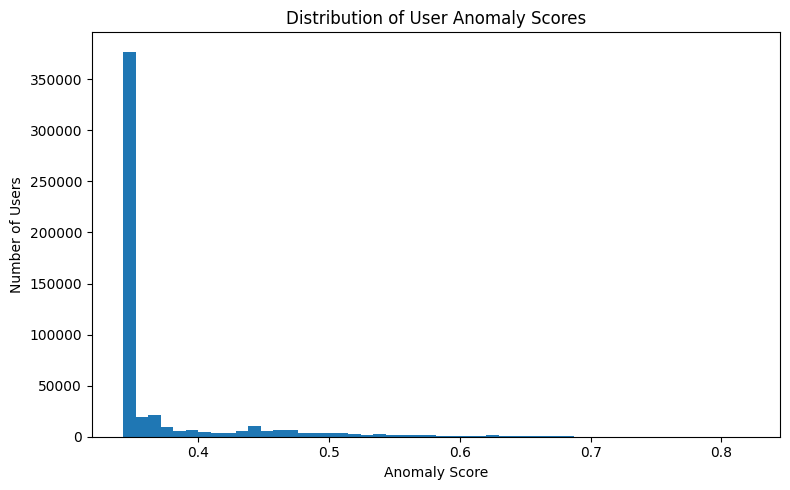

In [ ]:
# ============================================================
# ANOMALY SCORE DISTRIBUTION
# ============================================================

plt.figure(figsize=(8, 5))

plt.hist(
    train_anomaly_scores,
    bins=50
)

plt.xlabel("Anomaly Score")
plt.ylabel("Number of Users")

plt.title(
    "Distribution of User Anomaly Scores"
)

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/anomaly_scores.png",
    dpi=200
)

plt.show()

In [ ]:
# ============================================================
# POPULARITY MODEL
# ============================================================

def popularity_scores(
    data,
    weights=None
):

    if weights is None:

        scores = (
            data
            .groupby("itemid")
            .size()
        )

    else:

        temp = data[
            ["itemid"]
        ].copy()

        temp["weight"] = weights

        scores = (
            temp
            .groupby("itemid")["weight"]
            .sum()
        )

    return scores.sort_values(
        ascending=False
    )

In [ ]:
# ============================================================
# USER DICTIONARIES
# ============================================================

def make_seen_dict(data):

    return (
        data
        .groupby("visitorid")["itemid"]
        .agg(set)
        .to_dict()
    )


def make_truth_dict(data):

    return (
        data
        .groupby("visitorid")["itemid"]
        .agg(set)
        .to_dict()
    )

In [ ]:
# ============================================================
# RECOMMENDATION METRICS
# ============================================================

def evaluate_popularity(
    training_data,
    evaluation_data,
    weights=None,
    k_values=(5, 10),
    candidate_pool=1000
):

    popularity = popularity_scores(
        training_data,
        weights
    )

    candidates = (
        popularity
        .index
        .to_numpy()[:candidate_pool]
    )

    seen = make_seen_dict(
        training_data
    )

    truth = make_truth_dict(
        evaluation_data
    )

    max_k = max(k_values)

    totals = {
        k: {
            "precision": 0,
            "recall": 0,
            "ndcg": 0
        }

        for k in k_values
    }

    evaluated_users = 0

    for user, relevant_items in truth.items():

        if not relevant_items:
            continue

        seen_items = seen.get(
            user,
            set()
        )

        recommendations = []

        for item in candidates:

            if item not in seen_items:

                recommendations.append(
                    item
                )

            if len(recommendations) >= max_k:
                break

        if len(recommendations) == 0:
            continue

        evaluated_users += 1

        for k in k_values:

            top_k = recommendations[:k]

            hits = sum(
                item in relevant_items
                for item in top_k
            )

            precision = (
                hits / k
            )

            recall = (
                hits /
                len(relevant_items)
            )

            dcg = 0

            for rank, item in enumerate(top_k):

                if item in relevant_items:

                    dcg += (
                        1 /
                        np.log2(rank + 2)
                    )

            ideal_hits = min(
                k,
                len(relevant_items)
            )

            idcg = sum(
                1 /
                np.log2(rank + 2)

                for rank in range(
                    ideal_hits
                )
            )

            ndcg = (
                dcg / idcg
                if idcg > 0
                else 0
            )

            totals[k]["precision"] += (
                precision
            )

            totals[k]["recall"] += (
                recall
            )

            totals[k]["ndcg"] += (
                ndcg
            )

    results = []

    for k in k_values:

        results.append({

            "K": k,

            "Precision@K":
                totals[k]["precision"]
                / evaluated_users,

            "Recall@K":
                totals[k]["recall"]
                / evaluated_users,

            "NDCG@K":
                totals[k]["ndcg"]
                / evaluated_users,

            "Evaluated Users":
                evaluated_users
        })

    return pd.DataFrame(results)

In [ ]:
# ============================================================
# POPULARITY BASELINE
# ============================================================

baseline_validation = evaluate_popularity(
    train,
    validation,
    k_values=K_VALUES,
    candidate_pool=CANDIDATE_POOL
)

baseline_validation["Model"] = (
    "Popularity Baseline"
)

display(baseline_validation)

baseline_validation.to_csv(
    f"{OUTPUT_DIR}/baseline_validation.csv",
    index=False
)

,K,Precision@K,Recall@K,NDCG@K,Evaluated Users,Model
0,5,0.001264,0.005797,0.005337,121965,Popularity Baseline
1,10,0.000963,0.008396,0.006242,121965,Popularity Baseline


In [ ]:
# ============================================================
# CREATE ANOMALY WEIGHTS
# ============================================================

def create_anomaly_weights(
    scores,
    contamination,
    minimum_weight=0.25
):

    threshold = scores.quantile(
        1 - contamination
    )

    anomalous = (
        scores >= threshold
    )

    max_score = scores.max()

    strength = (
        (scores - threshold)
        /
        max(
            max_score - threshold,
            1e-12
        )
    ).clip(0, 1)

    weights = (
        1
        -
        (1 - minimum_weight)
        * strength
    )

    return (
        threshold,
        anomalous,
        weights
    )

In [ ]:
# ============================================================
# VALIDATION EXPERIMENT
# ============================================================

validation_results = []

for contamination in CONTAMINATION_GRID:

    (
        threshold,
        anomalous,
        user_weights
    ) = create_anomaly_weights(

        train_anomaly_scores,

        contamination,

        MIN_ANOMALY_WEIGHT
    )

    anomalous_users = set(
        train_anomaly_scores.index[
            anomalous
        ]
    )

    # --------------------------------------------------------
    # ANOMALY REMOVAL
    # --------------------------------------------------------

    removal_train = train[
        ~train["visitorid"].isin(
            anomalous_users
        )
    ].copy()

    removal_result = evaluate_popularity(
        removal_train,
        validation,
        k_values=[10],
        candidate_pool=CANDIDATE_POOL
    )

    validation_results.append({

        "Method":
            "Anomaly Removal",

        "Contamination":
            contamination,

        "Anomalous Users (%)":
            anomalous.mean() * 100,

        "Precision@10":
            removal_result.iloc[0]["Precision@K"],

        "Recall@10":
            removal_result.iloc[0]["Recall@K"],

        "NDCG@10":
            removal_result.iloc[0]["NDCG@K"]
    })

    # --------------------------------------------------------
    # DOWN-WEIGHTING
    # --------------------------------------------------------

    interaction_weights = (
        train["visitorid"]
        .map(user_weights)
        .fillna(1)
        .to_numpy()
    )

    downweight_result = evaluate_popularity(
        train,
        validation,
        weights=interaction_weights,
        k_values=[10],
        candidate_pool=CANDIDATE_POOL
    )

    validation_results.append({

        "Method":
            "Anomaly Down-weighting",

        "Contamination":
            contamination,

        "Anomalous Users (%)":
            anomalous.mean() * 100,

        "Precision@10":
            downweight_result.iloc[0]["Precision@K"],

        "Recall@10":
            downweight_result.iloc[0]["Recall@K"],

        "NDCG@10":
            downweight_result.iloc[0]["NDCG@K"]
    })

validation_results = pd.DataFrame(
    validation_results
)

display(validation_results)

validation_results.to_csv(
    f"{OUTPUT_DIR}/validation_results.csv",
    index=False
)

,Method,Contamination,Anomalous Users (%),Precision@10,Recall@10,NDCG@10
0,Anomaly Removal,0.01,1.000126,0.001029,0.008864,0.006400
1,Anomaly Down-weighting,0.01,1.000126,0.000980,0.008489,0.006281
2,Anomaly Removal,0.03,2.999996,0.001032,0.008877,0.006327
3,Anomaly Down-weighting,0.03,2.999996,0.000980,0.008489,0.006281
4,Anomaly Removal,0.05,5.000057,0.001034,0.008894,0.006416
5,Anomaly Down-weighting,0.05,5.000057,0.001021,0.008846,0.006387
6,Anomaly Removal,0.10,10.000306,0.001019,0.009069,0.006458
7,Anomaly Down-weighting,0.10,10.000306,0.001021,0.008846,0.006387


In [37]:

# Inspect down-weighting validation scores at full precision

downweight_validation = validation_results[
    validation_results["Method"] == "Anomaly Down-weighting"
][["Contamination", "Precision@10", "Recall@10", "NDCG@10"]]

print(
    downweight_validation.to_string(
        index=False,
        float_format=lambda x: f"{x:.12f}"
    )
)

print("\nDifference in NDCG@10 (10% minus 5%):")

scores = downweight_validation.set_index("Contamination")["NDCG@10"]
print(f"{scores.loc[0.10] - scores.loc[0.05]:.12f}")


 Contamination   Precision@10      Recall@10        NDCG@10
0.010000000000 0.000979789284 0.008488999526 0.006280634462
0.030000000000 0.000979789284 0.008488999526 0.006280634462
0.050000000000 0.001020784651 0.008845674990 0.006386904492
0.100000000000 0.001020784651 0.008845674990 0.006386904492

Difference in NDCG@10 (10% minus 5%):
0.000000000000


In [38]:

# Select the best validation settings
# Tie-breaking rule: prefer lower contamination when
# validation NDCG@10 is identical.

removal_results = validation_results[
    validation_results["Method"] == "Anomaly Removal"
].sort_values(
    ["NDCG@10", "Contamination"],
    ascending=[False, True]
)

downweight_results = validation_results[
    validation_results["Method"] == "Anomaly Down-weighting"
].sort_values(
    ["NDCG@10", "Contamination"],
    ascending=[False, True]
)

best_removal = removal_results.iloc[0]
best_downweight = downweight_results.iloc[0]

print("Best removal setting:")
print(best_removal)

print("\nBest down-weighting setting:")
print(best_downweight)


Best removal setting:
Method                 Anomaly Removal
Contamination                      0.1
Anomalous Users (%)          10.000306
Precision@10                  0.001019
Recall@10                     0.009069
NDCG@10                       0.006458
Name: 6, dtype: object

Best down-weighting setting:
Method                 Anomaly Down-weighting
Contamination                            0.05
Anomalous Users (%)                  5.000057
Precision@10                         0.001021
Recall@10                            0.008846
NDCG@10                              0.006387
Name: 5, dtype: object


In [ ]:
# ============================================================
# FINAL TRAINING DATA
# ============================================================

train_validation = pd.concat(
    [train, validation],
    ignore_index=True
)

train_validation = (
    train_validation
    .sort_values("timestamp")
    .reset_index(drop=True)
)

print(
    "Final training data:",
    train_validation.shape
)

Final training data: (1198726, 6)


In [ ]:
# ============================================================
# FINAL ANOMALY MODEL
# ============================================================

train_validation_features = (
    create_user_features(
        train_validation
    )
)

X_final = (
    train_validation_features.copy()
)

for column in log_columns:

    X_final[column] = np.log1p(
        X_final[column]
    )

final_scaler = StandardScaler()

X_final_scaled = (
    final_scaler.fit_transform(
        X_final
    )
)

sample_size = min(
    ANOMALY_SAMPLE_SIZE,
    len(X_final_scaled)
)

sample_indices = rng.choice(
    len(X_final_scaled),
    sample_size,
    replace=False
)

final_forest = IsolationForest(

    n_estimators=150,

    max_samples=10_000,

    contamination="auto",

    random_state=RANDOM_STATE,

    n_jobs=-1
)

final_forest.fit(
    X_final_scaled[
        sample_indices
    ]
)

final_scores = pd.Series(

    -final_forest.score_samples(
        X_final_scaled
    ),

    index=train_validation_features.index
)

In [ ]:
# ============================================================
# FINAL BASELINE ON TEST
# ============================================================

baseline_test = evaluate_popularity(
    train_validation,
    test,
    k_values=K_VALUES,
    candidate_pool=CANDIDATE_POOL
)

baseline_test["Model"] = (
    "Popularity Baseline"
)

display(baseline_test)

,K,Precision@K,Recall@K,NDCG@K,Evaluated Users,Model
0,5,0.001478,0.006375,0.005247,123656,Popularity Baseline
1,10,0.001140,0.009188,0.006172,123656,Popularity Baseline


In [ ]:
# ============================================================
# FINAL ANOMALY REMOVAL
# ============================================================

(
    threshold,
    anomalous,
    _
) = create_anomaly_weights(

    final_scores,

    best_removal["Contamination"],

    MIN_ANOMALY_WEIGHT
)

anomalous_users = set(
    final_scores.index[
        anomalous
    ]
)

removal_train = train_validation[
    ~train_validation["visitorid"]
    .isin(anomalous_users)
].copy()

removal_test = evaluate_popularity(
    removal_train,
    test,
    k_values=K_VALUES,
    candidate_pool=CANDIDATE_POOL
)

removal_test["Model"] = (
    "Anomaly Removal"
)

display(removal_test)

,K,Precision@K,Recall@K,NDCG@K,Evaluated Users,Model
0,5,0.001524,0.006787,0.005353,123656,Anomaly Removal
1,10,0.001190,0.010189,0.006472,123656,Anomaly Removal


In [ ]:
# ============================================================
# FINAL ANOMALY DOWN-WEIGHTING
# ============================================================

(
    threshold,
    anomalous,
    user_weights
) = create_anomaly_weights(

    final_scores,

    best_downweight["Contamination"],

    MIN_ANOMALY_WEIGHT
)

interaction_weights = (
    train_validation["visitorid"]
    .map(user_weights)
    .fillna(1)
    .to_numpy()
)

downweight_test = evaluate_popularity(
    train_validation,
    test,
    weights=interaction_weights,
    k_values=K_VALUES,
    candidate_pool=CANDIDATE_POOL
)

downweight_test["Model"] = (
    "Anomaly Down-weighting"
)

display(downweight_test)

,K,Precision@K,Recall@K,NDCG@K,Evaluated Users,Model
0,5,0.001478,0.006375,0.005247,123656,Anomaly Down-weighting
1,10,0.001062,0.008859,0.006059,123656,Anomaly Down-weighting


In [ ]:
# ============================================================
# FINAL RESULTS TABLE
# ============================================================

final_results = pd.concat(
    [
        baseline_test,
        removal_test,
        downweight_test
    ],
    ignore_index=True
)

final_results = final_results[
    [
        "Model",
        "K",
        "Precision@K",
        "Recall@K",
        "NDCG@K",
        "Evaluated Users"
    ]
]

display(final_results)

final_results.to_csv(
    f"{OUTPUT_DIR}/final_results.csv",
    index=False
)

,Model,K,Precision@K,Recall@K,NDCG@K,Evaluated Users
0,Popularity Baseline,5,0.001478,0.006375,0.005247,123656
1,Popularity Baseline,10,0.001140,0.009188,0.006172,123656
2,Anomaly Removal,5,0.001524,0.006787,0.005353,123656
3,Anomaly Removal,10,0.001190,0.010189,0.006472,123656
4,Anomaly Down-weighting,5,0.001478,0.006375,0.005247,123656
5,Anomaly Down-weighting,10,0.001062,0.008859,0.006059,123656


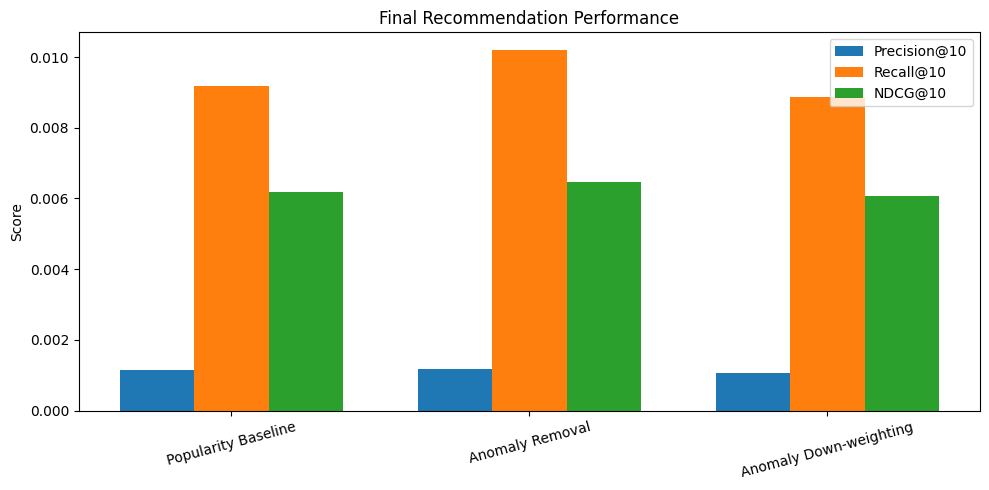

In [ ]:
# ============================================================
# FINAL RESULTS VISUALIZATION
# ============================================================

plot_data = final_results[
    final_results["K"] == 10
]

models = plot_data["Model"].tolist()

x = np.arange(len(models))

width = 0.25

plt.figure(figsize=(10, 5))

plt.bar(
    x - width,
    plot_data["Precision@K"],
    width,
    label="Precision@10"
)

plt.bar(
    x,
    plot_data["Recall@K"],
    width,
    label="Recall@10"
)

plt.bar(
    x + width,
    plot_data["NDCG@K"],
    width,
    label="NDCG@10"
)

plt.xticks(
    x,
    models,
    rotation=15
)

plt.ylabel("Score")

plt.title(
    "Final Recommendation Performance"
)

plt.legend()

plt.tight_layout()

plt.savefig(
    f"{OUTPUT_DIR}/final_comparison.png",
    dpi=200
)

plt.show()

In [ ]:
# ============================================================
# ANOMALY STATISTICS
# ============================================================

final_threshold = final_scores.quantile(
    1 - best_removal["Contamination"]
)

final_anomalous = (
    final_scores >= final_threshold
)

final_anomalous_users = set(
    final_scores.index[
        final_anomalous
    ]
)

anomalous_interactions = (
    train_validation["visitorid"]
    .isin(final_anomalous_users)
)

anomaly_summary = pd.DataFrame({

    "Metric": [

        "Users",

        "Anomalous users",

        "Anomalous users (%)",

        "Interactions",

        "Interactions from anomalous users",

        "Anomalous interactions (%)"
    ],

    "Value": [

        len(final_scores),

        final_anomalous.sum(),

        final_anomalous.mean() * 100,

        len(train_validation),

        anomalous_interactions.sum(),

        anomalous_interactions.mean() * 100
    ]
})

display(anomaly_summary)

anomaly_summary.to_csv(
    f"{OUTPUT_DIR}/anomaly_summary.csv",
    index=False
)

,Metric,Value
0,Users,6.357220e+05
1,Anomalous users,6.357600e+04
2,Anomalous users (%),1.000060e+01
3,Interactions,1.198726e+06
4,Interactions from anomalous users,4.417350e+05
5,Anomalous interactions (%),3.685037e+01


In [ ]:
display(baseline_validation)

,K,Precision@K,Recall@K,NDCG@K,Evaluated Users,Model
0,5,0.001264,0.005797,0.005337,121965,Popularity Baseline
1,10,0.000963,0.008396,0.006242,121965,Popularity Baseline


In [ ]:

import pandas as pd
from pathlib import Path

path = Path("results/baseline_validation.csv")

if path.exists():
    baseline_validation = pd.read_csv(path)
    display(baseline_validation)
else:
    print("Baseline validation CSV not found.")


,K,Precision@K,Recall@K,NDCG@K,Evaluated Users,Model
0,5,0.001264,0.005797,0.005337,121965,Popularity Baseline
1,10,0.000963,0.008396,0.006242,121965,Popularity Baseline
